## 1. Get the Data

In [5]:
from tdc.multi_pred import TrialOutcome

data = TrialOutcome(name='phase1').get_data()

Downloading...
100%|██████████| 7.75M/7.75M [00:01<00:00, 5.46MiB/s]
Loading...
Done!


In [10]:
data.shape

(2402, 7)

In [8]:
data.head()

,nctid,start_date,complete_date,drug_molecules,icdcodes,eligibility_criteria,Y
0,NCT00002790,March 1996,NaN,CC[C@@H]1NC(=O)[C@H]([C@H](O)[C@H](C)C\\C=C\\C...,D89.810__D89.811__D89.813__D89.812__C95.91__C9...,DISEASE CHARACTERISTICS: See General Eligibili...,0
1,NCT00002863,June 1996,July 2000,[H][C@@]12N(C)C3=CC(OC)=C(C=C3[C@@]11CCN3CC=C[...,C96.A__C46.9__C96.22__C46.0__C46.2__C92.31__C9...,DISEASE CHARACTERISTICS: Biopsy-proven soft ti...,0
2,NCT00003005,December 1997,March 2001,[H][C@@]1(CO)C[C@@]([H])(O)[C@@]([H])(O1)N1C=N...,C95.91__C95.92__Z80.6__Z85.6__C90.11__C90.12__...,DISEASE CHARACTERISTICS: TdT positive acute ly...,0
3,NCT00003060,March 1995,"February 22, 2001",CS(=O)(=O)OCCCCOS(C)(=O)=O__ClCCN(CCCl)P1(=O)N...,C43.51__C43.9__C43.52__D03.51__C43.8__Z85.820_...,DISEASE CHARACTERISTICS: Biopsy proven relapse...,0
4,NCT00003194,July 1997,"December 19, 2002",N[C@@H](CCCNC(N)=N)C(O)=O__ClCCN(CCCl)P1(=O)NC...,H01.009__H02.209__H02.009__H02.109__H04.209__H...,DISEASE CHARACTERISTICS: - Histologically prov...,0


In [11]:
# Drop the chemical molecules column
clean_raw_df = data.drop(columns=['drug_molecules'])

# 2. Export to csv
clean_raw_df.to_csv('data/clinical_trials_raw.csv', index=False)

Now, we have the data in a csv that we can work with.  
If you are trying to reproduce this notebook, you do not need to install the huge `pytdc` package. You can just rely on the csv.

## 2. Exploratory Data Analysis (EDA)

In [13]:
import pandas as pd

df = pd.read_csv('data/clinical_trials_raw.csv')

In [15]:
df.dtypes

nctid                   object
start_date              object
complete_date           object
icdcodes                object
eligibility_criteria    object
Y                        int64
dtype: object

In [16]:
df.head()

,nctid,start_date,complete_date,icdcodes,eligibility_criteria,Y
0,NCT00002790,March 1996,NaN,D89.810__D89.811__D89.813__D89.812__C95.91__C9...,DISEASE CHARACTERISTICS: See General Eligibili...,0
1,NCT00002863,June 1996,July 2000,C96.A__C46.9__C96.22__C46.0__C46.2__C92.31__C9...,DISEASE CHARACTERISTICS: Biopsy-proven soft ti...,0
2,NCT00003005,December 1997,March 2001,C95.91__C95.92__Z80.6__Z85.6__C90.11__C90.12__...,DISEASE CHARACTERISTICS: TdT positive acute ly...,0
3,NCT00003060,March 1995,"February 22, 2001",C43.51__C43.9__C43.52__D03.51__C43.8__Z85.820_...,DISEASE CHARACTERISTICS: Biopsy proven relapse...,0
4,NCT00003194,July 1997,"December 19, 2002",H01.009__H02.209__H02.009__H02.109__H04.209__H...,DISEASE CHARACTERISTICS: - Histologically prov...,0


In [17]:
df.shape

(2402, 6)

In [18]:
df.isnull().sum()

nctid                    0
start_date              13
complete_date           21
icdcodes                 0
eligibility_criteria     0
Y                        0
dtype: int64

In [19]:
df['Y'].value_counts()

Y
1    1371
0    1031
Name: count, dtype: int64

In [20]:
df['Y'].value_counts(normalize=True) * 100

Y
1    57.077435
0    42.922565
Name: proportion, dtype: float64

In [21]:
df['nctid'].nunique()

2402

### 2.1 Dataset Schema and Feature Engineering Layout

We can get the meaning of the columns directly from the Therapeutics Data Commons (TDC) schema documentation: https://tdcommons.ai/multi_pred_tasks/trialoutcome/#trial-outcome-prediction-top

*   **`nctid` (Categorical String / Primary Key):** 
    *   **Definition:** The unique National Clinical Trial Identifier assigned by the US government registry (`ClinicalTrials.gov`) to track each clinical study globally. 
    *   **Pipeline Action:** Maintained as a unique row identifier; excluded from model training to prevent arbitrary indexing bias.
*   **`start_date` (Date String):** 
    *   **Definition:** The calendar month and year when the clinical trial officially began enrolling its first cohort of patient participants.
    *   **Engineered Outputs:** 
        *   `start_year` (Numerical/Categorical): Extracted to isolate and control for historical changes in FDA regulatory stringency.
        *   `start_month` (Numerical/Categorical): Extracted to capture potential seasonal operational variations in trial launches.
*   **`complete_date` (Date String):** 
    *   **Definition:** The date when the final participant was examined or received intervention for final primary outcome evaluations. 
    *   **Engineered Outputs:** 
        *   `duration_days` (Numerical): Calculated via temporal subtraction (`complete_date - start_date`). This evaluates the exact timeline profile of the study. Missing completion dates (frequent in truncated or terminated trials) are explicitly handled with a sentinel numerical flag (`-1`).
*   **`icdcodes` (Delimited String List):** 
    *   **Definition:** International Classification of Diseases (ICD-10) medical codes representing the precise target indications or patient comorbidities, separated by a double underscore (`__`).
    *   **Engineered Outputs:** 
        *   `num_conditions` (Numerical): A count derived by splitting the string on the delimiter. This acts as a proxy variable for baseline trial complexity; managing a patient cohort with 10 co-morbidities carries inherently higher operational friction than managing a single-indication study.
        *   `primary_disease_chapter` (Categorical): Extracted using the very first letter of the primary ICD code. In medicine, this letter isolates the broad physiological therapeutic area (e.g., `C` = Neoplasms/Oncology, `I` = Circulatory System). This maps to a high-value category ready for one-hot encoding.
*   **`eligibility_criteria` (Unstructured Free Text):** 
    *   **Definition:** The raw free-text clinical protocol write-up listing the exact participant entry rules, laboratory thresholds, and clinical exclusions.
    *   **Engineered Outputs:** 
        *   `criteria_word_count` (Numerical): Structural metric evaluating text mass. Massive, text-dense criteria sheets indicate highly granular protocol constraints, acting as a strong mathematical proxy for enrollment bottlenecks.
        *   `exclusion_keyword_count` (Numerical): An algorithmic keyword density extraction matching restrictive phrasing (`exclude`, `exclusion`, `no history of`, `prior concurrent`). A high density indicates strict baseline filtering criteria, drastically lowering the eligible patient pool and amplifying delivery risk.
*   **`Y` (Binary Integer):** 
    *   **Definition:** **The Target Variable.** This is the binary metric we aim to forecast.
    *   **Classes:** 
        *   `1` (**Success**): The trial successfully met its clinical protocols, hit its target endpoints, and was successfully completed.
        *   `0` (**Failure**): The trial was prematurely terminated, suspended, or withdrawn due to clinical toxicity, poor efficacy, or strategic budget cuts.

In [22]:
# Extract temporal structures
df['start_dt'] = pd.to_datetime(df['start_date'], errors='coerce')
df['complete_dt'] = pd.to_datetime(df['complete_date'], errors='coerce')

df['start_year'] = df['start_dt'].dt.year
df['start_month'] = df['start_dt'].dt.month
df['duration_days'] = (df['complete_dt'] - df['start_dt']).dt.days

# Extract nested indication structures
df['num_conditions'] = df['icdcodes'].apply(lambda x: len(str(x).split('__')) if pd.notnull(x) else 0)
df['primary_disease_chapter'] = df['icdcodes'].apply(lambda x: str(x)[0] if pd.notnull(x) and len(str(x)) > 0 else 'Unknown')

import re

# Extract protocol metrics from free-text
df['criteria_word_count'] = df['eligibility_criteria'].apply(lambda x: len(str(x).split()) if pd.notnull(x) else 0)
df['exclusion_keyword_count'] = df['eligibility_criteria'].apply(
    lambda x: sum(1 for _ in re.finditer(r'(?i)\b(exclude|exclusion|no history|prior concurrent)\b', str(x))) if pd.notnull(x) else 0
)

# Filter out messy text columns to create the final tabular data matrix
features = ['nctid', 'start_year', 'start_month', 'duration_days', 'num_conditions', 'primary_disease_chapter', 'criteria_word_count', 'exclusion_keyword_count', 'Y']

## 2.2 Missing Values

In [25]:
df.isnull().sum()

nctid                       0
start_date                 13
complete_date              21
icdcodes                    0
eligibility_criteria        0
Y                           0
start_dt                   13
complete_dt                21
start_year                 13
start_month                13
duration_days              28
num_conditions              0
primary_disease_chapter     0
criteria_word_count         0
exclusion_keyword_count     0
dtype: int64

In [27]:
df[features].isnull().sum()

nctid                       0
start_year                 13
start_month                13
duration_days              28
num_conditions              0
primary_disease_chapter     0
criteria_word_count         0
exclusion_keyword_count     0
Y                           0
dtype: int64

In [28]:
df[features].head()

,nctid,start_year,start_month,duration_days,num_conditions,primary_disease_chapter,criteria_word_count,exclusion_keyword_count,Y
0,NCT00002790,1996.0,3.0,NaN,14,D,136,1,0
1,NCT00002863,1996.0,6.0,1491.0,7,C,177,2,0
2,NCT00003005,1997.0,12.0,1186.0,7,C,113,1,0
3,NCT00003060,1995.0,3.0,2185.0,7,C,148,3,0
4,NCT00003194,1997.0,7.0,1997.0,7,H,287,2,0


In [29]:
df['duration_days'] = df['duration_days'].fillna(-1).astype(int)
df['start_year'] = df['start_year'].fillna(-1).astype(int)
df['start_month'] = df['start_month'].fillna(-1).astype(int)

In [31]:
df[features].isnull().sum()

nctid                      0
start_year                 0
start_month                0
duration_days              0
num_conditions             0
primary_disease_chapter    0
criteria_word_count        0
exclusion_keyword_count    0
Y                          0
dtype: int64

### 2.3 Target Variable Analysis

In [32]:
df['Y'].value_counts()

Y
1    1371
0    1031
Name: count, dtype: int64

In [33]:
df['Y'].value_counts(normalize=True) * 100

Y
1    57.077435
0    42.922565
Name: proportion, dtype: float64

In [35]:
target_counts = df['Y'].value_counts()
target_percentages = df['Y'].value_counts(normalize=True) * 100

balance_profile = pd.DataFrame({
    'Total Count': target_counts,
    'Percentage (%)': target_percentages
})

print(balance_profile)

   Total Count  Percentage (%)
Y                             
1         1371       57.077435
0         1031       42.922565


In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

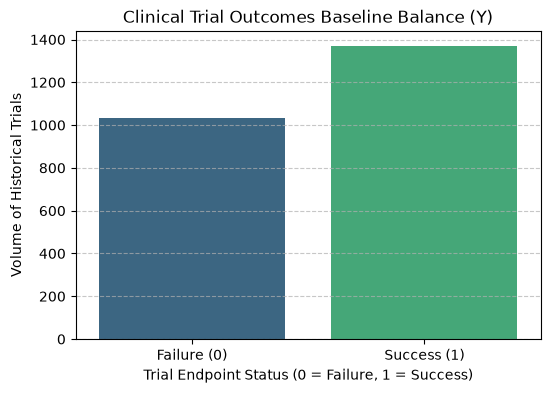

In [48]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Y', palette='viridis')

plt.title('Clinical Trial Outcomes Baseline Balance (Y)')
plt.xlabel('Trial Endpoint Status (0 = Failure, 1 = Success)')
plt.ylabel('Volume of Historical Trials')
plt.xticks([0, 1], ['Failure (0)', 'Success (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)

### 2.4 Numerical Feature Distribution & Variable Ranges

In [36]:
numerical_features = ['duration_days', 'num_conditions', 'criteria_word_count', 'exclusion_keyword_count']

# Generate descriptive summary table
numerical_summary = df[numerical_features].describe()
print(numerical_summary)

       duration_days  num_conditions  criteria_word_count  \
count    2402.000000     2402.000000          2402.000000   
mean     1024.308077       10.708160           449.279351   
std       828.294556       23.316739           325.711952   
min        -1.000000        1.000000             3.000000   
25%       417.750000        6.000000           196.000000   
50%       862.500000        7.000000           395.500000   
75%      1405.500000        7.000000           607.750000   
max      6600.000000      547.000000          2220.000000   

       exclusion_keyword_count  
count              2402.000000  
mean                  1.233555  
std                   0.706363  
min                   0.000000  
25%                   1.000000  
50%                   1.000000  
75%                   1.000000  
max                  19.000000  


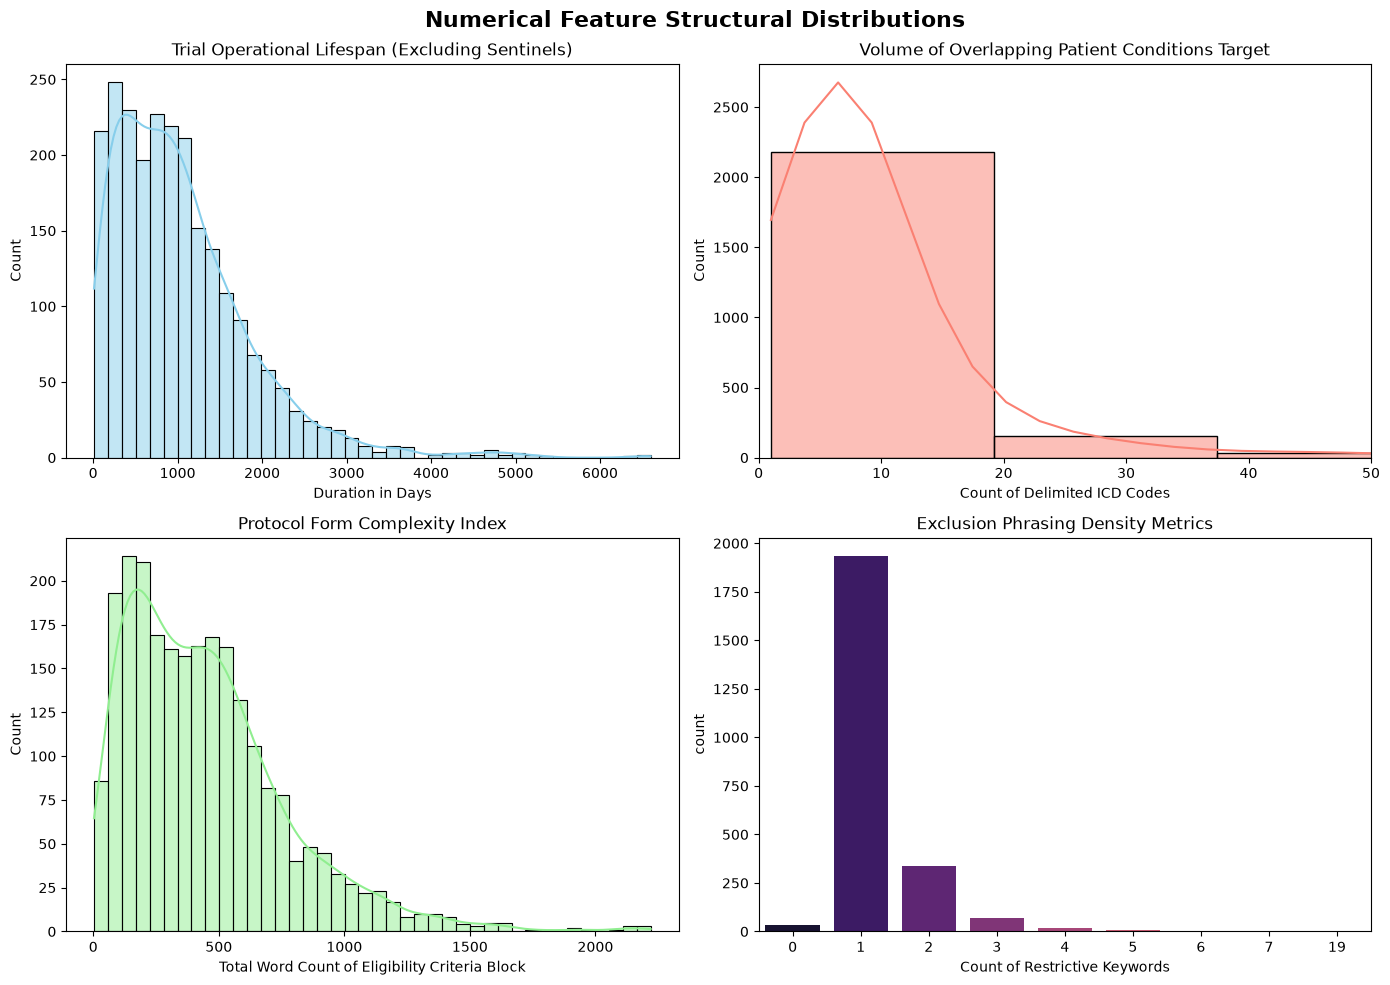

In [49]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Numerical Feature Structural Distributions', fontsize=16, weight='bold')

# 1. Timeline Duration
sns.histplot(df[df['duration_days'] > 0]['duration_days'], bins=40, ax=axes[0,0], color='skyblue', kde=True)
axes[0,0].set_title('Trial Operational Lifespan (Excluding Sentinels)')
axes[0,0].set_xlabel('Duration in Days')

# 2. Condition Overlap
sns.histplot(df['num_conditions'], bins=30, ax=axes[0,1], color='salmon', kde=True)
axes[0,1].set_title('Volume of Overlapping Patient Conditions Target')
axes[0,1].set_xlabel('Count of Delimited ICD Codes')
axes[0,1].set_xlim(0, 50) # Zooming in on primary bulk due to extreme 547 max outlier

# 3. Protocol Density
sns.histplot(df['criteria_word_count'], bins=40, ax=axes[1,0], color='lightgreen', kde=True)
axes[1,0].set_title('Protocol Form Complexity Index')
axes[1,0].set_xlabel('Total Word Count of Eligibility Criteria Block')

# 4. Restriction Keyword Counts
sns.countplot(data=df, x='exclusion_keyword_count', ax=axes[1,1], palette='magma')
axes[1,1].set_title('Exclusion Phrasing Density Metrics')
axes[1,1].set_xlabel('Count of Restrictive Keywords')

plt.tight_layout()
plt.show()

### 2.5 Feature Importance Analysis

In [37]:
from sklearn.metrics import mutual_info_score

In [42]:
# 1. Compute Mutual Information Score
mi_score = mutual_info_score(df['primary_disease_chapter'], df['Y'])
print(f"Mutual Information Score (primary_disease_chapter vs Y): {mi_score:.5f}")

Mutual Information Score (primary_disease_chapter vs Y): 0.01830


In [45]:
# 2. Analyze the Baseline Success Rates by Primary Medical Chapter
chapter_stats = df.groupby('primary_disease_chapter')['Y'].agg(['count', 'mean']).reset_index()
chapter_stats.columns = ['Disease Chapter', 'Total Trials Included', 'Historical Success Rate (PoS)']

# Sort by success rate descending to see the performance spread
chapter_stats = chapter_stats.sort_values(by='Historical Success Rate (PoS)', ascending=False).reset_index(drop=True)

print("Risk Profile by Disease Category:")
print(chapter_stats)

Risk Profile by Disease Category:
   Disease Chapter  Total Trials Included  Historical Success Rate (PoS)
0                B                     79                       0.759494
1                E                    174                       0.758621
2                K                    116                       0.706897
3                J                     50                       0.680000
4                Y                      6                       0.666667
5                H                     68                       0.647059
6                L                     42                       0.642857
7                G                     85                       0.623529
8                P                     13                       0.615385
9                M                     54                       0.611111
10               Z                    125                       0.608000
11               S                    128                       0.585938
12               

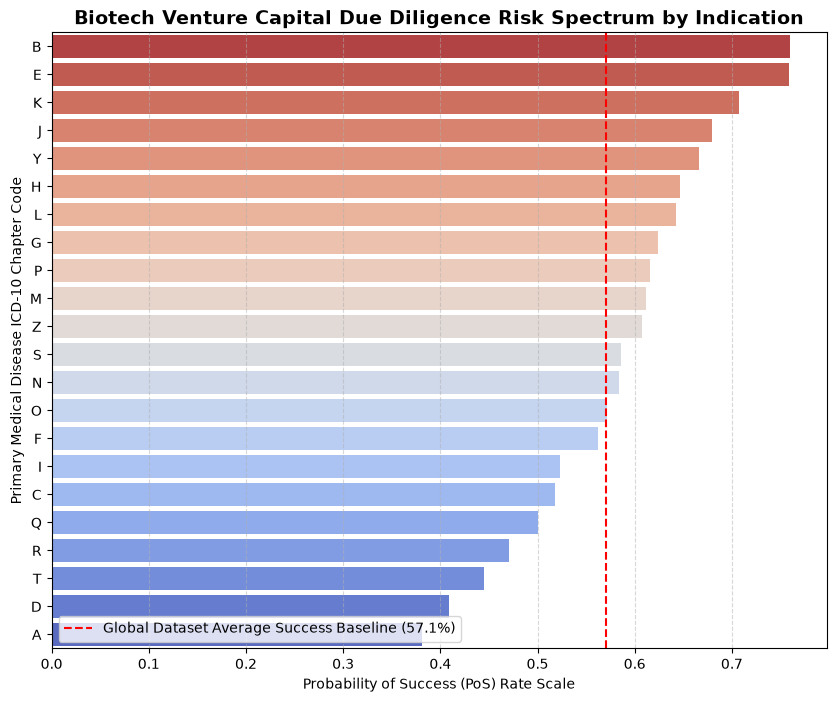

In [50]:
plt.figure(figsize=(10, 8))

# Use the sorted chapter_stats dataframe generated in your previous step
sns.barplot(
    data=chapter_stats, 
    x='Historical Success Rate (PoS)', 
    y='Disease Chapter', 
    palette='coolwarm_r'
)

# Reference line showing the global naive average success baseline (~57%)
plt.axvline(x=0.5707, color='red', linestyle='--', linewidth=1.5, label='Global Dataset Average Success Baseline (57.1%)')

plt.title('Biotech Venture Capital Due Diligence Risk Spectrum by Indication', fontsize=14, weight='bold')
plt.xlabel('Probability of Success (PoS) Rate Scale')
plt.ylabel('Primary Medical Disease ICD-10 Chapter Code')
plt.legend(loc='lower left')
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.show()

## 3. Validation Framework and Encoding

### 3.1 Dataset Truncation & Shuffled Partitioning

Filter `df` to isolate only our chosen modeling columns, generate a random shuffled index using a fixed random seed (`42`), and break the dataset into clean dataframes: 60% Train, 20% Validation, and 20% Test.

In [ ]:
# 1. Truncate df down to only our selected modeling attributes
features_to_use = [
    'start_year', 'start_month', 'duration_days', 'num_conditions', 
    'primary_disease_chapter', 'criteria_word_count', 'exclusion_keyword_count', 'Y'
]
df = df[features_to_use].copy()

In [54]:
df.head()

,start_year,start_month,duration_days,num_conditions,primary_disease_chapter,criteria_word_count,exclusion_keyword_count,Y
0,1996,3,-1,14,D,136,1,0
1,1996,6,1491,7,C,177,2,0
2,1997,12,1186,7,C,113,1,0
3,1995,3,2185,7,C,148,3,0
4,1997,7,1997,7,H,287,2,0


In [52]:
# 2. Compute partition row index markers
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

In [53]:
# 3. Create shuffled index mask using seed 42
import numpy as np
idx = np.arange(n)
np.random.seed(42)
np.random.shuffle(idx)

In [55]:
# 4. Shuffle and split dataframes
df_shuffled = df.iloc[idx].reset_index(drop=True)

df_train = df_shuffled.iloc[:n_train].copy()
df_val = df_shuffled.iloc[n_train:n_train+n_val].copy()
df_test = df_shuffled.iloc[n_train+n_val:].copy()

### 3.2 Target Matrix Isolation

Pull out the target variable vector (`Y`) from each split into independent numpy arrays (`y_train`, `y_val`, `y_test`) and completely drop the column from the dataframes to prevent look-ahead target leakage.

In [56]:
# Isolate Target Arrays
y_train = df_train['Y'].values
y_val = df_val['Y'].values
y_test = df_test['Y'].values

In [57]:
# Drop target variable completely from feature tracking frames
df_train = df_train.drop(columns=['Y']).reset_index(drop=True)
df_val = df_val.drop(columns=['Y']).reset_index(drop=True)
df_test = df_test.drop(columns=['Y']).reset_index(drop=True)

In [58]:
df_train.head()

,start_year,start_month,duration_days,num_conditions,primary_disease_chapter,criteria_word_count,exclusion_keyword_count
0,2008,6,518,3,C,452,1
1,2003,4,999,7,C,12,0
2,2013,4,1987,7,S,833,1
3,2013,6,2099,7,I,152,1
4,2010,2,638,6,D,753,2


A quick note here on why `start_year` and `start_month` matter to predict clinical trial success. 

In clinical trial operations and venture capital evaluation, these variables function as powerful macro-level proxies:

1. **`start_year` (Regulatory Eras & Venture Capital Macro-Cycles):**
   * **Regulatory Shifting:** The FDA constantly amends its stringency guidelines, compliance requirements, and safety benchmarks. A Phase 1 trial launched in 2005 navigated a completely different regulatory environment than one launched in 2023 under modern adaptive design protocols. The year allows tree models to control for these historical regulatory eras.
   * **Capital Environments:** Biotechnology is an incredibly capital-intensive sector. Trials launched during macroeconomic downturns or "biotech funding winters" face strict capital constraints, making them structurally more susceptible to premature abandonment or termination due to budget cuts rather than scientific failure. 

2. **`start_month` (Operational Seasonality and Patient Recruitment Bottlenecks):**
   * **Enrollment Friction:** The number-one operational bottleneck in clinical development is patient recruitment. Historically, global patient enrollment numbers plummet during winter holiday windows (November-January) and peak summer vacation blocks (July-August). 
   * **Cascading Delays:** A trial initialized immediately prior to a seasonal slowdown frequently experiences immediate enrollment lag. In Phase 1 operations, missing initial momentum can cause compounding timeline extensions, driving up overhead costs and magnifying execution risk.

### 3.3 Categorical One-Hot Encoding via DictVectorizer

Convert our split dataframes into standard Python dictionary lists using `.to_dict(orient='records')`. Then, instantiate scikit-learn's `DictVectorizer(sparse=False)`.

We `.fit_transform()` on `df_train` to establish the spatial mapping matrices (`X_train`), then sequentially use `.transform()` on `df_val` and `df_test` to generate `X_val` and `X_test` without re-learning the dictionary definitions.

In [61]:
# 1. Convert split DataFrames into lists of standard Python dictionaries
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')
test_dicts = df_test.to_dict(orient='records')

In [62]:
from sklearn.feature_extraction import DictVectorizer

In [63]:
# 2. Instantiate scikit-learn's DictVectorizer setting sparse=False for flat numpy arrays
dv = DictVectorizer(sparse=False)

In [64]:
# 3. Fit the mapping logic and transform exclusively on the training records
X_train = dv.fit_transform(train_dicts)

In [65]:
# 4. Transform validation and test records using the already learned training features
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

In [66]:
print(f"X_train shape: {X_train.shape} | X_val shape: {X_val.shape} | X_test shape: {X_test.shape}")

X_train shape: (1442, 28) | X_val shape: (480, 28) | X_test shape: (480, 28)


In [67]:
print(f"Total encoded features tracked by DictVectorizer: {len(dv.get_feature_names_out())}")

Total encoded features tracked by DictVectorizer: 28


## 4. Training the Models and Tuning their Parameters

### 4.1 Logistic Regression

In [68]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [69]:
# 1. Define the grid scale of inverse regularization strengths to sweep
c_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

best_c = None
best_lr_auc = -1
lr_tuning_results = []

In [70]:
# 2. Systematically loop through each hyperparameter option
for c in c_values:
    # Instantiate linear model with the active regularization hyperparameter
    model_lr = LogisticRegression(solver='lbfgs', C=c, max_iter=1000, random_state=42)
    
    # Fit the weights using the training partitions
    model_lr.fit(X_train, y_train)
    
    # Predict success probabilities for the validation subset
    y_pred_val = model_lr.predict_proba(X_val)[:, 1]
    
    # Evaluate performance using ROC AUC
    auc = roc_auc_score(y_val, y_pred_val)
    
    # Track the history logs
    lr_tuning_results.append({'C': c, 'ROC_AUC': auc})
    print(f"Parameter Config [C={c:7.3f}] -> Validation ROC AUC: {auc:.5f}")
    
    # Update performance tracker if this validation score beats our historical best
    if auc > best_lr_auc:
        best_lr_auc = auc
        best_c = c

print("--- Logistic Regression Tuning Summary ---")
print(f"Optimal Parameter: C = {best_c}")
print(f"Highest Validation ROC AUC Achieved: {best_lr_auc:.5f}")

Parameter Config [C=  0.001] -> Validation ROC AUC: 0.53252
Parameter Config [C=  0.010] -> Validation ROC AUC: 0.54586
Parameter Config [C=  0.100] -> Validation ROC AUC: 0.56611
Parameter Config [C=  1.000] -> Validation ROC AUC: 0.56155
Parameter Config [C= 10.000] -> Validation ROC AUC: 0.56289
Parameter Config [C=100.000] -> Validation ROC AUC: 0.56166
--- Logistic Regression Tuning Summary ---
Optimal Parameter: C = 0.1
Highest Validation ROC AUC Achieved: 0.56611


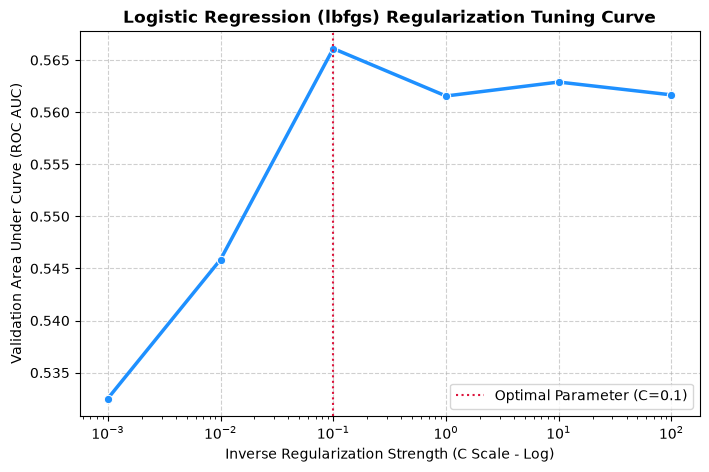

In [72]:
# Convert history records into a clean dataframe
tuning_df = pd.DataFrame(lr_tuning_results)

plt.figure(figsize=(8, 5))
sns.lineplot(data=tuning_df, x='C', y='ROC_AUC', marker='o', linewidth=2.5, color='dodgerblue')

plt.xscale('log') # Exponential step scale requires log X-axis to distribute points evenly
plt.title('Logistic Regression (lbfgs) Regularization Tuning Curve', fontsize=12, weight='bold')
plt.xlabel('Inverse Regularization Strength (C Scale - Log)')
plt.ylabel('Validation Area Under Curve (ROC AUC)')
plt.grid(True, linestyle='--', alpha=0.6)

# Highlight the selected peak configuration
plt.axvline(x=best_c, color='crimson', linestyle=':', label=f'Optimal Parameter (C={best_c})')
plt.legend(loc='lower right')

plt.show()

In [73]:
# 3. Permanently train and lock in the final optimized baseline model using the best C parameter
final_model_lr = LogisticRegression(solver='lbfgs', C=best_c, max_iter=1000, random_state=42)
final_model_lr.fit(X_train, y_train)
print("Optimized baseline Logistic Regression model locked and ready.")

Optimized baseline Logistic Regression model locked and ready.


### 4.2 Random Forest

In [74]:
from sklearn.ensemble import RandomForestClassifier

In [75]:
# Define the precise tuning parameter spaces
depths = [5, 10, 15, 20]
estimators_range = [10, 25, 50, 100, 150, 200]

rf_tuning_results = []
best_rf_auc = -1
best_rf_config = {}

# Systematic nested loop to search the parameter space grid
for depth in depths:
    print(f"Sweeping estimator capacities for max_depth = {depth}...")
    for n_est in estimators_range:
        # Instantiate the ensemble model with active parameters
        model_rf = RandomForestClassifier(
            n_estimators=n_est, 
            max_depth=depth, 
            random_state=42, 
            n_jobs=-1 # Uses all processor cores for accelerated execution
        )
        
        # Fit the forest trees onto the training metrics
        model_rf.fit(X_train, y_train)
        
        # Estimate validation probabilities
        y_pred_val = model_rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred_val)
        
        # Store metadata logs
        rf_tuning_results.append({
            'max_depth': depth, 
            'n_estimators': n_est, 
            'ROC_AUC': auc
        })
        
        if auc > best_rf_auc:
            best_rf_auc = auc
            best_rf_config = {'n_estimators': n_est, 'max_depth': depth}

print("--- Random Forest Tuning Summary ---")
print(f"Optimal Structural Configuration: {best_rf_config}")
print(f"Highest Validation ROC AUC Achieved: {best_rf_auc:.5f}")

Sweeping estimator capacities for max_depth = 5...
Sweeping estimator capacities for max_depth = 10...
Sweeping estimator capacities for max_depth = 15...
Sweeping estimator capacities for max_depth = 20...
--- Random Forest Tuning Summary ---
Optimal Structural Configuration: {'n_estimators': 50, 'max_depth': 10}
Highest Validation ROC AUC Achieved: 0.64761


In [77]:
rf_tuning_df = pd.DataFrame(rf_tuning_results)
rf_tuning_df

,max_depth,n_estimators,ROC_AUC
0,5,10,0.615714
1,5,25,0.630455
2,5,50,0.628429
3,5,100,0.617679
4,5,150,0.620018
5,5,200,0.623125
6,10,10,0.632250
7,10,25,0.643946
8,10,50,0.647607
9,10,100,0.640768


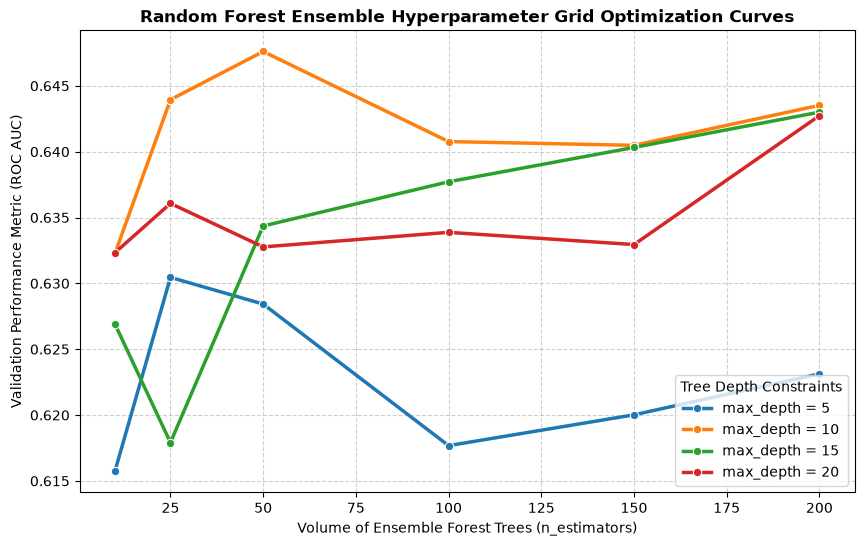

In [ ]:
# Convert max_depth to string categories to ensure distinct graph hues
rf_tuning_df['max_depth_str'] = 'max_depth = ' + rf_tuning_df['max_depth'].astype(str)

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=rf_tuning_df, 
    x='n_estimators', 
    y='ROC_AUC', 
    hue='max_depth_str', 
    marker='o', 
    linewidth=2.5
)

plt.title('Random Forest Ensemble Hyperparameter Grid Optimization Curves', fontsize=12, weight='bold')
plt.xlabel('Volume of Ensemble Forest Trees (n_estimators)')
plt.ylabel('Validation Performance Metric (ROC AUC)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Tree Depth Constraints')

plt.show()

In [78]:
# Train and lock in the final optimized forest instance
final_model_rf = RandomForestClassifier(**best_rf_config, random_state=42, n_jobs=-1)
final_model_rf.fit(X_train, y_train)
print("Optimized Random Forest model permanently saved.")

Optimized Random Forest model permanently saved.


* **Performance Lift:** Our optimal configuration (`max_depth=10`, `n_estimators=50`) achieved a peak Validation ROC AUC of **0.64761**, significantly outperforming the baseline Logistic Regression model (**0.56611**). This ~8.1% absolute leap confirms that complex, non-linear interactions among clinical trial features are crucial for predicting risk.
* **Model Selection:** Restricting the model to a depth of 10 and 50 trees captures peak performance without unnecessary overhead.
* **The Plateau vs. Overfitting:** Notice that allowing the model to grow deeper (`max_depth=15` or `20`) does not cause performance to plummet. Because Random Forests rely on ensemble averaging (bagging), they are inherently resistant to catastrophic overfitting. Instead, the validation score simply plateaus around **0.642**, meaning deeper trees add computational weight without providing any extra predictive power.

### 4.3 Gradient Boosting (XGBoost)

In [79]:
import xgboost as xgb

In [80]:
# 1. Convert flat numpy feature arrays into high-performance native DMatrix profiles
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=dv.get_feature_names_out().tolist())
dval = xgb.DMatrix(X_val, label=y_val, feature_names=dv.get_feature_names_out().tolist())

In [81]:
# 2. Define the baseline hyperparameter configuration dictionary
base_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'max_depth': 6,
    'min_child_weight': 1,
    'seed': 42,
    'nthread': -1
}

In [82]:
# Define the scale of learning rates (eta) to sweep
eta_values = [0.01, 0.05, 0.1, 0.3]
num_boost_round = 200

# Setup dictionary logs to store history metrics across training paths
eta_histories = {}

# 3. Systematically sweep across learning rates
for eta in eta_values:
    print(f"Growing boosting rounds for learning rate eta = {eta}...")
    
    # Clone baseline configurations and append active learning rate
    active_params = base_params.copy()
    active_params['eta'] = eta
    
    # Watchlist tracks evaluation metrics on both training and validation sets simultaneously
    watchlist = [(dtrain, 'train'), (dval, 'val')]
    evals_result = {}
    
    # Train the boosting engine
    model_xgb = xgb.train(
        active_params,
        dtrain,
        num_boost_round=num_boost_round,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=False
    )
    
    # Store history loops into dataframe logs
    df_history = pd.DataFrame({
        'round': np.arange(num_boost_round),
        'train_auc': evals_result['train']['auc'],
        'val_auc': evals_result['val']['auc']
    })
    
    eta_histories[f'eta_{eta}'] = df_history

Growing boosting rounds for learning rate eta = 0.01...
Growing boosting rounds for learning rate eta = 0.05...
Growing boosting rounds for learning rate eta = 0.1...
Growing boosting rounds for learning rate eta = 0.3...


In [85]:
# Print out the absolute peak validation scores for each learning rate
for eta in [0.01, 0.05, 0.1, 0.3]:
    df_hist = eta_histories[f'eta_{eta}']
    best_idx = df_hist['val_auc'].idxmax()
    best_row = df_hist.loc[best_idx]
    print(f"Learning Rate [eta={eta:<4}] -> Peak Validation AUC: {best_row['val_auc']:.5f} at Round {int(best_row['round'])}")

Learning Rate [eta=0.01] -> Peak Validation AUC: 0.62780 at Round 110
Learning Rate [eta=0.05] -> Peak Validation AUC: 0.63077 at Round 23
Learning Rate [eta=0.1 ] -> Peak Validation AUC: 0.62943 at Round 9
Learning Rate [eta=0.3 ] -> Peak Validation AUC: 0.63547 at Round 11


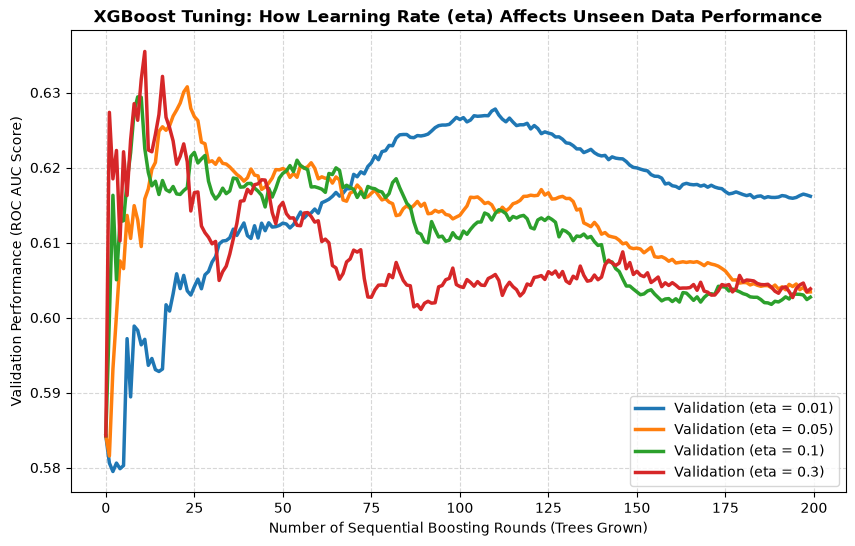

In [87]:
plt.figure(figsize=(10, 6))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# Plot ONLY the validation lines to keep the evaluation perfectly clear
for (key, df_hist), col in zip(eta_histories.items(), colors):
    # key maps to 'eta_0.01', 'eta_0.05', etc.
    clean_label = key.replace('_', ' = ')
    plt.plot(df_hist['round'], df_hist['val_auc'], label=f'Validation ({clean_label})', color=col, linewidth=2.5)

plt.title('XGBoost Tuning: How Learning Rate (eta) Affects Unseen Data Performance', fontsize=12, weight='bold')
plt.xlabel('Number of Sequential Boosting Rounds (Trees Grown)')
plt.ylabel('Validation Performance (ROC AUC Score)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

plt.show()

* `eta = 0.3`: Climbs aggressively to a volatile initial peak (**0.635**), but plummets immediately after. Large optimization steps force the model to memorize training noise rapidly, leading to classic high-variance overfitting.
* `eta = 0.01`: Taking tiny steps delays convergence significantly. It takes over 100 rounds just to form a broad, stable hill, making it computationally slow for our target timeline constraints.
* `eta = 0.05`: Striking a solid balance, it climbs smoothly and holds onto its predictive plateau longer than `0.3` before gradually decaying, showing better resilience to immediate noise.
* `eta = 0.1`: The **`eta = 0.1`** configuration was selected for the next tuning steps. It delivers the ideal blend of operational speed and structural stability, hitting a predictable plateau early.


We tuned for an `eta`. Now let's tune for the `max_depth`.

In [88]:
# Lock in our selected eta learning rate sweet spot
depth_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'eta': 0.1,  # Standard baseline learning rate
    'min_child_weight': 1,
    'seed': 42,
    'nthread': -1
}

# Define explicit depth tiers to test
depth_values = [3, 4, 6, 10]
num_boost_round = 200
depth_histories = {}

# Systematically sweep through depth tiers inline
for depth in depth_values:
    print(f"Growing boosting rounds for max_depth = {depth}...")
    
    active_params = depth_params.copy()
    active_params['max_depth'] = depth
    
    watchlist = [(dtrain, 'train'), (dval, 'val')]
    evals_result = {}
    
    model_xgb = xgb.train(
        active_params,
        dtrain,
        num_boost_round=num_boost_round,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=False
    )
    
    # Store clean history logs into our dictionary dataframe maps
    depth_histories[f'depth_{depth}'] = pd.DataFrame({
        'round': np.arange(num_boost_round),
        'train_auc': evals_result['train']['auc'],
        'val_auc': evals_result['val']['auc']
    })

print("Depth optimization calculations complete!")

Growing boosting rounds for max_depth = 3...
Growing boosting rounds for max_depth = 4...
Growing boosting rounds for max_depth = 6...
Growing boosting rounds for max_depth = 10...
Depth optimization calculations complete!


In [90]:
# Print out the absolute peak validation scores for each tree depth
for depth in depth_values:
    df_hist = depth_histories[f'depth_{depth}']
    best_idx = df_hist['val_auc'].idxmax()
    best_row = df_hist.loc[best_idx]
    print(f"Tree Depth [max_depth={depth:<2}] -> Peak Validation AUC: {best_row['val_auc']:.5f} at Round {int(best_row['round'])}")

Tree Depth [max_depth=3 ] -> Peak Validation AUC: 0.64316 at Round 69
Tree Depth [max_depth=4 ] -> Peak Validation AUC: 0.63770 at Round 39
Tree Depth [max_depth=6 ] -> Peak Validation AUC: 0.62943 at Round 9
Tree Depth [max_depth=10] -> Peak Validation AUC: 0.62004 at Round 47


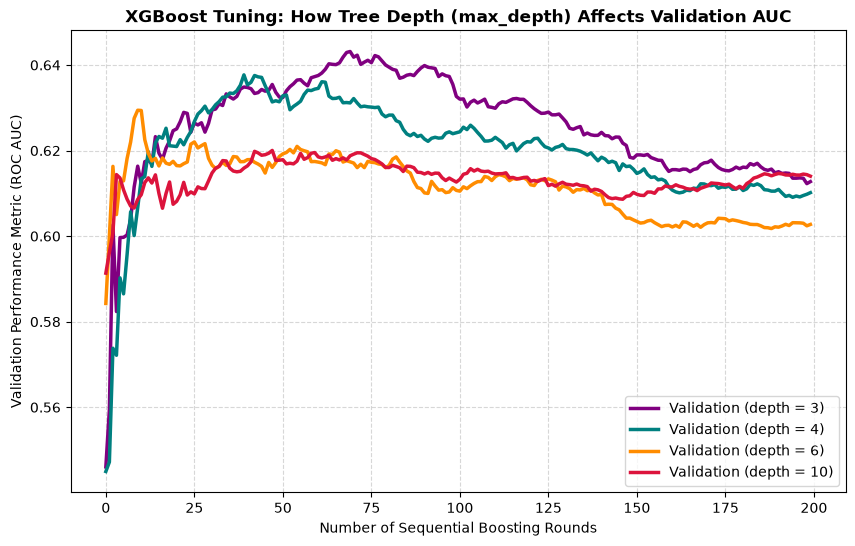

In [91]:
plt.figure(figsize=(10, 6))

depth_colors = ['purple', 'teal', 'darkorange', 'crimson']
for (key, df_hist), col in zip(depth_histories.items(), depth_colors):
    clean_label = key.replace('_', ' = ')
    plt.plot(df_hist['round'], df_hist['val_auc'], label=f'Validation ({clean_label})', color=col, linewidth=2.5)

plt.title('XGBoost Tuning: How Tree Depth (max_depth) Affects Validation AUC', fontsize=12, weight='bold')
plt.xlabel('Number of Sequential Boosting Rounds')
plt.ylabel('Validation Performance Metric (ROC AUC)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

plt.show()

* `max_depth = 3`: Shallow trees achieve the highest peak validation score (**0.64316 at Round 69**). Keeping each sequential tree simple prevents it from capturing unique noise variations, allowing the boosting ensemble to generalize smoothly to unseen validation rows.
* `max_depth = 6 & 10`: Allowing deeper cuts causes performance to drop or peak prematurely (e.g., depth 6 peaks at just Round 9). Deeper structures provide too much capacity, causing the algorithm to aggressively memorize training splits instead of mapping broad trends.

A maximum depth of 3 produced the highest validation score and was selected for the next tuning step.


Now let's tune for `min_child_weight`.

In [92]:
# Lock in our tuned configurations
mcw_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'eta': 0.1,
    'max_depth': 3,  # Our newly selected tree depth winner
    'seed': 42,
    'nthread': -1
}

# Define explicit child weight values to evaluate
mcw_values = [1, 5, 10]
num_boost_round = 200
mcw_histories = {}

# Systematically sweep through values inline
for mcw in mcw_values:
    print(f"Growing boosting rounds for min_child_weight = {mcw}...")
    
    active_params = mcw_params.copy()
    active_params['min_child_weight'] = mcw
    
    watchlist = [(dtrain, 'train'), (dval, 'val')]
    evals_result = {}
    
    model_xgb = xgb.train(
        active_params,
        dtrain,
        num_boost_round=num_boost_round,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=False
    )
    
    # Inline clean parsing
    mcw_histories[f'mcw_{mcw}'] = pd.DataFrame({
        'round': np.arange(num_boost_round),
        'train_auc': evals_result['train']['auc'],
        'val_auc': evals_result['val']['auc']
    })

print("Weight optimization calculations complete!")

Growing boosting rounds for min_child_weight = 1...
Growing boosting rounds for min_child_weight = 5...
Growing boosting rounds for min_child_weight = 10...
Weight optimization calculations complete!


In [94]:
for mcw in mcw_values:
    df_hist = mcw_histories[f'mcw_{mcw}']
    best_row = df_hist.loc[df_hist['val_auc'].idxmax()]
    print(f"Child Weight min_child_weight={mcw:<2} -> Peak Validation AUC: {best_row['val_auc']:.5f} at Round {int(best_row['round'])}")


Child Weight min_child_weight=1  -> Peak Validation AUC: 0.64316 at Round 69
Child Weight min_child_weight=5  -> Peak Validation AUC: 0.62232 at Round 36
Child Weight min_child_weight=10 -> Peak Validation AUC: 0.61673 at Round 68


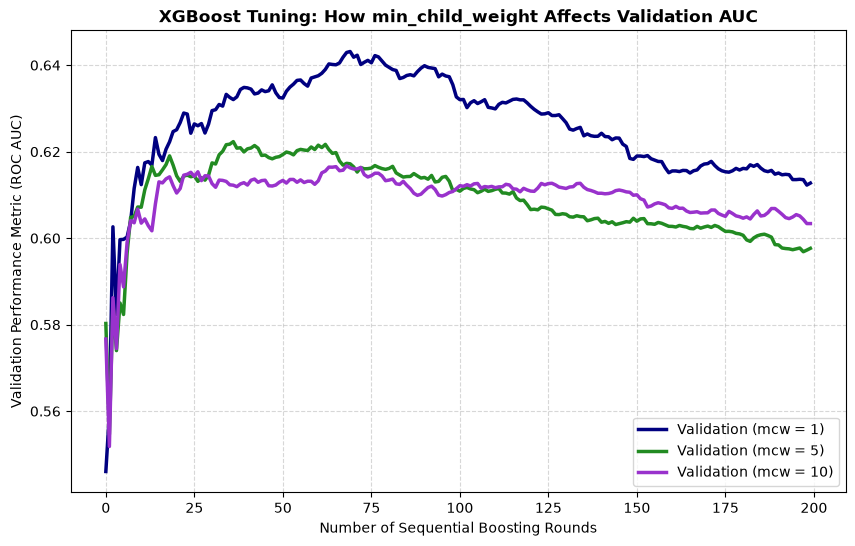

In [95]:
plt.figure(figsize=(10, 6))

mcw_colors = ['navy', 'forestgreen', 'darkorchid']
for (key, df_hist), col in zip(mcw_histories.items(), mcw_colors):
    clean_label = key.replace('_', ' = ')
    plt.plot(df_hist['round'], df_hist['val_auc'], label=f'Validation ({clean_label})', color=col, linewidth=2.5)

plt.title('XGBoost Tuning: How min_child_weight Affects Validation AUC', fontsize=12, weight='bold')
plt.xlabel('Number of Sequential Boosting Rounds')
plt.ylabel('Validation Performance Metric (ROC AUC)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

plt.show()

* `min_child_weight = 1`: Setting the minimum child weight to 1 yields the optimal peak validation score (**0.64316 at Round 69**). Given our tight, high-signal tabular feature matrix, allowing fine-grained leaf partition groups captures subtle operational risk indicators safely.
* `min_child_weight = 5 & 10`: Increasing the weight threshold degrades predictive power.

The best XGBoost configuration in this tuning exercise was: **`eta = 0.1`**, **`max_depth = 3`**, **`min_child_weight = 1`**, trained for **69 boosting rounds**.

Validation ROC AUC scores:
1. Logistic Regression (Baseline): 0.56611
2. XGBoost Classifier: 0.64316
3. Random Forest Classifier (Winner): 0.64761

### 4.4 Full Train and Final Test

In [97]:
# 1. Recombine train and validation splits to leverage maximum data assets
df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)
y_full_train = np.concatenate([y_train, y_val])

print(f"Full Train Matrix Size: {df_full_train.shape} | Hold-out Test Matrix Size: {df_test.shape}")

# 2. Convert to dictionary structures for vectorization
full_train_dicts = df_full_train.to_dict(orient='records')
test_dicts = df_test.to_dict(orient='records')

# 3. Fit fresh dictionary mappings on the full training pool
dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(full_train_dicts)
X_test = dv_final.transform(test_dicts)

# 4. Instantiate and train the definitive Champion Random Forest model
final_production_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)
final_production_model.fit(X_full_train, y_full_train)
print("Production Random Forest model fully trained on combined data asset pool.")

# 5. Predict probabilities and calculate the absolute final performance metric
y_pred_test = final_production_model.predict_proba(X_test)[:, 1]
final_test_auc = roc_auc_score(y_test, y_pred_test)

print("=================================================")
print(f"OFFICIAL GENERALISATION TEST ROC AUC: {final_test_auc:.5f}")
print("====================================================")

Full Train Matrix Size: (1922, 7) | Hold-out Test Matrix Size: (480, 7)
Production Random Forest model fully trained on combined data asset pool.
OFFICIAL GENERALISATION TEST ROC AUC: 0.63286


The Random Forest achieved a validation ROC AUC of 0.64761 and a hold-out test ROC AUC of 0.63286. Its test score is lower than its validation score, so the results show some generalization beyond the training data but do not establish that the model is free of overfitting. 

The validation ROC AUC was 0.08150 (8.15 percentage points) higher than Logistic Regression’s 0.56611.

## 5. Deployment

In [103]:
from sklearn.pipeline import Pipeline
import pickle

print("Assembling native scikit-learn production pipeline...")

# 1. Define the step sequence: first vectorize categories, then fit the forest
production_pipeline = Pipeline([
    ('vectorizer', DictVectorizer(sparse=False)),
    ('classifier', RandomForestClassifier(
        n_estimators=50,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Fit the entire pipeline directly onto our raw full train dictionary list
# The pipeline handles passing the data through each step internally!
production_pipeline.fit(full_train_dicts, y_full_train)
print("Production pipeline successfully fitted on full training pool.")

# 3. Double-check that it generalizes perfectly by validating on test dicts
y_pred_pipe = production_pipeline.predict_proba(test_dicts)[:, 1]
pipe_test_auc = roc_auc_score(y_test, y_pred_pipe)
print(f"Verified Pipeline Test ROC AUC: {pipe_test_auc:.5f} (Matches the previous score!)")

# 4. Serialize the entire pipeline assembly into a single file artifact
output_file = 'notebook_model.bin'
print(f"Serialising single pipeline asset to: {output_file}")

with open(output_file, 'wb') as f_out:
    pickle.dump(production_pipeline, f_out)

print("Single pipeline artifact successfully packaged and locked!")

Assembling native scikit-learn production pipeline...
Production pipeline successfully fitted on full training pool.
Verified Pipeline Test ROC AUC: 0.63286 (Matches the previous score!)
Serialising single pipeline asset to: notebook_model.bin
Single pipeline artifact successfully packaged and locked!


In [101]:
!jupyter nbconvert --to script notebook.ipynb --output train

[NbConvertApp] Converting notebook notebook.ipynb to script
[NbConvertApp] Writing 33804 bytes to train.py
